<a href="https://colab.research.google.com/github/nithar6891-ux/DL-UNIT-TEST/blob/main/Next_Word_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:


!pip install tensorflow scikit-learn

In [ ]:


import re

with open("/content/1661-0.txt", "r", encoding="utf-8") as f:
    text = f.read()

text = re.sub(r"\s+", " ", text)

sentences = re.split(r"(?<=[.!?])\s+", text)

sentences = [
    s.strip().lower()
    for s in sentences
    if len(s.split()) >= 2
]

sentences = sentences[:10000]

print("Total sentences:", len(sentences))
print("\nFirst five sentences:")

for s in sentences[:5]:
    print(s)

Total sentences: 5096

First five sentences:
﻿ project gutenberg's the adventures of sherlock holmes, by arthur conan doyle this ebook is for the use of anyone anywhere at no cost and with almost no restrictions whatsoever.
you may copy it, give it away or re-use it under the terms of the project gutenberg license included with this ebook or online at www.gutenberg.net title: the adventures of sherlock holmes author: arthur conan doyle release date: november 29, 2002 [ebook #1661] last updated: may 20, 2019 language: english character set encoding: utf-8 *** start of this project gutenberg ebook the adventures of sherlock holmes *** produced by an anonymous project gutenberg volunteer and jose menendez cover the adventures of sherlock holmes by arthur conan doyle contents i.
a scandal in bohemia ii.
the red-headed league iii.
a case of identity iv.


In [ ]:


from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenize sentences
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(sentences)

vocab_size = len(tokenizer.word_index) + 1

# Generate input-target sequences
sequences = []

for sentence in sentences:
    tokens = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(1, len(tokens)):
        sequences.append(tokens[:i + 1])

# Pad sequences
max_len = max(len(seq) for seq in sequences)

padded = pad_sequences(
    sequences,
    maxlen=max_len,
    padding="pre"
)

X = padded[:, :-1]
y = padded[:, -1]

print("Vocabulary size:", vocab_size)
print("Total sequences:", len(sequences))
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Vocabulary size: 8914
Total sequences: 105941
Input shape: (105941, 250)
Target shape: (105941,)


In [ ]:


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create LSTM model
model = Sequential([
    Embedding(vocab_size, 64, mask_zero=True),
    LSTM(64),
    Dropout(0.2),
    Dense(vocab_size, activation="softmax")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        "sparse_categorical_accuracy",
        __import__("tensorflow").keras.metrics
        .SparseTopKCategoricalAccuracy(
            k=5, name="top5_accuracy"
        )
    ]
)

# Display model details
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:


model.build(input_shape=(None, X.shape[1]))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 64)        │       570,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8914)           │       579,410 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,182,930 (4.51 MB)

 Trainable params: 1,182,930 (4.51 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:


history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
1192/1192 ━━━━━━━━━━━━━━━━━━━━ 332s 274ms/step - loss: 6.7221 - sparse_categorical_accuracy: 0.0529 - top5_accuracy: 0.1590 - val_loss: 6.5003 - val_sparse_categorical_accuracy: 0.0631 - val_top5_accuracy: 0.1870
Epoch 2/5
1192/1192 ━━━━━━━━━━━━━━━━━━━━ 375s 268ms/step - loss: 6.2166 - sparse_categorical_accuracy: 0.0729 - top5_accuracy: 0.2074 - val_loss: 6.3128 - val_sparse_categorical_accuracy: 0.0847 - val_top5_accuracy: 0.2275
Epoch 3/5
1192/1192 ━━━━━━━━━━━━━━━━━━━━ 324s 272ms/step - loss: 5.9202 - sparse_categorical_accuracy: 0.0971 - top5_accuracy: 0.2481 - val_loss: 6.1479 - val_sparse_categorical_accuracy: 0.1044 - val_top5_accuracy: 0.2585
Epoch 4/5
1192/1192 ━━━━━━━━━━━━━━━━━━━━ 323s 271ms/step - loss: 5.7000 - sparse_categorical_accuracy: 0.1113 - top5_accuracy: 0.2712 - val_loss: 6.0747 - val_sparse_categorical_accuracy: 0.1169 - val_top5_accuracy: 0.2716
Epoch 5/5
1192/1192 ━━━━━━━━━━━━━━━━━━━━ 379s 268ms/step - loss: 5.5358 - sparse_categorical_accuracy: 0.122

In [8]:

results = model.evaluate(X_test, y_test, verbose=1)

print("Test Loss:", results[0])
print("Top-1 Accuracy:", results[1] * 100, "%")
print("Top-5 Accuracy:", results[2] * 100, "%")


663/663 ━━━━━━━━━━━━━━━━━━━━ 35s 53ms/step - loss: 5.9941 - sparse_categorical_accuracy: 0.1157 - top5_accuracy: 0.2801
Test Loss: 5.994071006774902
Top-1 Accuracy: 11.572042107582092 %
Top-5 Accuracy: 28.005096316337585 %


In [10]:

import numpy as np

def predict_next_words(phrase, k=5):
    tokens = tokenizer.texts_to_sequences([phrase.lower()])[0]

    if not tokens:
        print("Please enter known words.")
        return

    seq = pad_sequences(
        [tokens],
        maxlen=X.shape[1],
        padding="pre"
    )

    probs = model.predict(seq, verbose=0)[0]
    probs[0] = 0

    top_ids = np.argsort(probs)[-k:][::-1]

    print("\nInput:", phrase)
    print("Predicted next words:")

    for idx in top_ids:
        word = tokenizer.index_word.get(int(idx), "?")
        print(word, ":", round(float(probs[idx]) * 100, 2), "%")


predict_next_words("how are")
predict_next_words("thank you")
predict_next_words("i want to")
predict_next_words("once upon a")



Input: how are
Predicted next words:
a : 5.95 %
the : 3.53 %
not : 2.69 %
to : 1.86 %
no : 1.82 %

Input: thank you
Predicted next words:
have : 3.47 %
was : 3.31 %
had : 3.13 %
not : 2.33 %
” : 2.11 %

Input: i want to
Predicted next words:
the : 7.76 %
be : 5.94 %
a : 3.09 %
me : 2.3 %
his : 1.96 %

Input: once upon a
Predicted next words:
little : 1.23 %
man : 1.09 %
very : 0.76 %
room : 0.73 %
own : 0.69 %


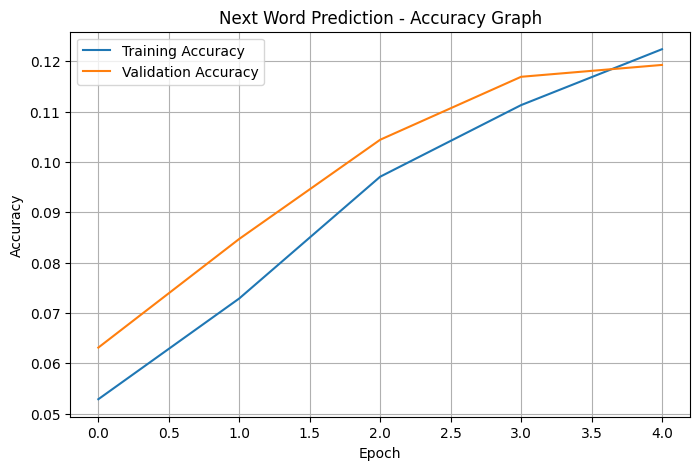

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["sparse_categorical_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_sparse_categorical_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Next Word Prediction - Accuracy Graph")
plt.legend()
plt.grid(True)
plt.show()
